# Stable cell lines expressing TfR1 orthologs viral titers

In [1]:
# Imports
import os
import warnings
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt, ticker as mticker

from scipy.interpolate import splrep, splev

# Plotting colors
tol_muted_adjusted = [
    "#000000",
    "#CC6677", 
    "#1f78b4", 
    "#DDCC77", 
    "#117733", 
    "#882255", 
    "#88CCEE",
    "#44AA99", 
    "#999933", 
    "#AA4499", 
    "#EE7733",
    "#CC3311",
    "#DDDDDD",
]

# Seaborn style settings
sns.set(rc={
    "figure.dpi":300, 
    "savefig.dpi":300,
    "svg.fonttype":"none",
})
sns.set_style("ticks")
sns.set_palette(tol_muted_adjusted)

# Suppress warnings
warnings.simplefilter("ignore")

In [2]:
# Read data
titer_data = pd.read_excel("Data/032526_titer_calculations.xlsx")
# Set output directory
out_dir = "Figures/"

In [3]:
# Re-group dataframe
titer_data = titer_data[["Infection_sample", "Titers_(TU/mL)"]]
titer_data["VEP"] = titer_data["Infection_sample"].str.contains("JUNV_")
titer_data["VEP"] = titer_data["VEP"].map({True: "Junin GPC", False: "VSV-G"})
titer_data["Infection_sample"] = titer_data["Infection_sample"].str.replace("JUNV_", "")
titer_data["Infection_sample"] = titer_data["Infection_sample"].str.replace("VSVG_", "")
# titer_data["Infection_sample"] = titer_data["Infection_sample"].str.replace(
#     "C_musculinus_EU164541_TfR1_TFRC_KO", 
#     "293T\u0394TFRC+C musculinus TfR1"
# )
# titer_data["Infection_sample"] = titer_data["Infection_sample"].str.replace(
#     "C_callosus_TfR1_TFRC_KO", 
#     "293T\u0394TFRC+C callosus TfR1"
# )
titer_data

,Infection_sample,Titers_(TU/mL),VEP
0,TFRC_KO,9.579935e+05,VSV-G
1,TFRC_KO,7.975963e+02,Junin GPC
2,293T,1.844136e+06,VSV-G
3,293T,1.043876e+04,Junin GPC
4,C_musculinus_EU164541_TfR1_TFRC_KO,8.141937e+05,Junin GPC
5,C_callosus_TfR1_TFRC_KO,4.918212e+05,Junin GPC
6,C_musculinus_EU164541_TfR1_TFRC_KO,5.544722e+06,VSV-G
7,C_callosus_TfR1_TFRC_KO,3.759706e+06,VSV-G


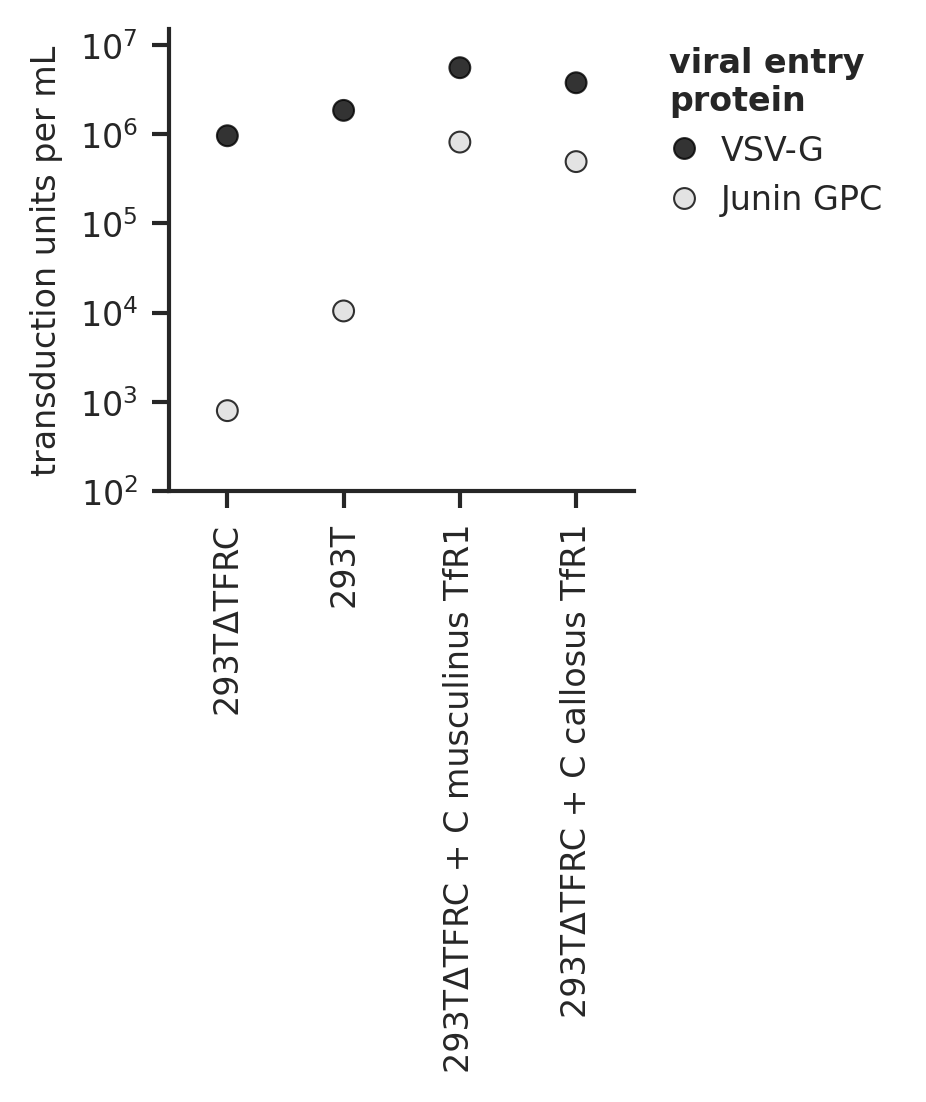

In [4]:
# Plot data
plt.figure(figsize=(2,2))
chart = sns.swarmplot(
    data=titer_data, 
    x="Infection_sample", 
    y="Titers_(TU/mL)", 
    hue="VEP", 
    alpha=0.8,
    edgecolor="black",
    linewidth=0.5,
    palette={"Junin GPC" : "#DDDDDD", "VSV-G" : "#000000"},
)
chart.set_yscale("log")
chart.yaxis.set_minor_locator(mticker.NullLocator())  # no minor ticks
chart.set_ylim(100, 15000000)
yticks = [100, 1000, 10000, 100000, 1000000, 10000000]
chart.set_yticks(yticks)
chart.set_yticklabels(labels=["$10^2$", "$10^3$", "$10^4$", "$10^5$", "$10^6$", "$10^7$"], fontsize=8)
xticks = [0, 1, 2, 3,]
chart.set_xticks(xticks)
x_labels = [
    "293T\u0394TFRC", 
    "293T", 
    "293T\u0394TFRC + C musculinus TfR1", 
    "293T\u0394TFRC + C callosus TfR1",
]
chart.set_xticklabels(labels=x_labels, rotation=90, horizontalalignment="center", fontsize=8)
chart.set_ylabel("transduction units per mL", fontsize=8)
chart.set(xlabel=None)
sns.move_legend(
    chart, 
    "upper left", 
    bbox_to_anchor=(1, 1),
    fontsize=8,
    markerscale=1,
    handletextpad=0.1,
    title="viral entry\nprotein",
    title_fontproperties = {
        "size" : 8, 
        "weight" : "bold",
    },
    frameon=False,
    borderaxespad=0.1,
)

# Change all spines
for axis in ["top", "bottom", "left", "right"]:
    chart.spines[axis].set_linewidth(1)
chart.tick_params(axis="both", length=4, width=1)

chart.grid(False)
sns.despine()

# Make output dir if doesn't exist
if not os.path.exists(out_dir):
    os.mkdir(out_dir)

# Save fig
plt.savefig(out_dir + "stable_cell_line_titers.svg")